# Lecture : Integrating GNNs and LLMs

## Lab 02 : G-Retriever with LLMs, GNNs and GraphRAG -- Solution

### Xavier Bresson, Ryoji Kubo

He, Tian, Sun, Chawla, Laurent, LeCun, Bresson, Hooi, G-Retriever: Retrieval-Augmented Generation for Textual Graph Understanding and Question Answering, 2024, https://arxiv.org/abs/2402.07630


In [1]:
# For Google Colaboratory
# Go to Runtime → Change runtime type → Select T4 GPU to accelerate LM embedding computation
import sys, os
if "google.colab" in sys.modules:
    # mount google drive
    from google.colab import drive
    drive.mount('/content/gdrive')
    path_to_file = '/content/gdrive/My Drive/CS5284_2026_codes/08_LLMs_GNNs'
    print(path_to_file)
    # change current path to the folder containing "path_to_file"
    os.chdir(path_to_file)
    !pwd
    !pip -q install -f https://data.dgl.ai/wheels/torch-2.6/repo.html dgl==2.5.0 # Install DGL
    # Install pcst_fast
    import importlib.util, subprocess, sys
    if importlib.util.find_spec('pcst_fast') is None: 
      subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pybind11>=2.13', 'setuptools_scm', 'wheel'])
      subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--no-build-isolation', '--no-deps', '--no-binary=pcst-fast', 'pcst-fast==1.0.10'])


## G-Retriever on Cora : Which two research classes does a paper bridge ?

**Learning goal:** Given a *TARGET* paper in the Cora citation network, predict *two research classes* that are structurally close to it. This is a fundamentally a graph-based question, not the original single Cora classification label task. For example, a paper connected by short citation paths to both `Neural_Networks` and `Probabilistic_Methods` classes is labeled as bridging those two classes.

Training set: We construct teaching labels (here the two classes that are the closest to the target paper) from shortest paths and a few paper anchors per class.

Workflow: We load the CORA citation graph → encode paper text → choose labeled class anchors and build two-class targets → retrieve an evidence subgraph with PCST → compare a standard full-graph GCN with sparse GraphRAG.

In this notebook, the retrieved PCST evidence is defined as the query-specific citation subgraph, including its selected papers and edges, connected class anchors, paths within the retrieved subgraph and neighboring paper titles.

<table align="center"> <tr> <td align="center"> <img src="pic/workflow.png" width="700"> </td> </tr> </table>

Two models: The Full-GCN model uses the entire citation graph. The G-Retriever model combines a 21-dimensional structural feature vector, a GCN on a query-specific Prize-Collecting Steiner Tree (PCST), and a trainable head on frozen SmolLM2 prompt embeddings.


## Load Cora dataset and build the citation graph

We first install the required dependencies and load the three Cora files: `cora.content`, `cora.cites` and `cora_text.csv`.

File `cora.cites` defines citation links, which are converted into an undirected DGL graph with self-loops. `cora.cites` $\rightarrow$ `g_full` (bidirectional citation graph with self-loops) and `neighbors` (adjacency lists without self-loops).

File `cora_text.csv` provides paper titles and abstracts. `cora_text.csv` $\rightarrow$ `node_texts` (combined title and abstract for language-model encoding).

File `cora.content` provides bag-of-words (BoW) features and original paper classes. `cora.content` $\rightarrow$ `x_bow` (row-normalized BoW features) and `y_cora` (paper class indices).

Let $c_{vj}$ denote the BoW value of word $j$ in paper $v$ (typically 0 or 1). Each paper's feature vector is normalized as

$$
x^{\mathrm{BoW}}_{vj}=\frac{c_{vj}}{\max\!\left(1,\sum_k c_{vk}\right)}.
$$

Thus, each nonzero BoW row sums to one, while an all-zero row remains zero.


In [2]:
# Disable Hugging Face Xet transfers to use the standard model download mechanism,
# preventing any downloading issue
import os
os.environ['HF_HUB_DISABLE_XET'] = '1'

# Import utilities for checking installed packages, detecting the operating system, and running installation commands
import importlib.util
import platform
import subprocess
import sys

# Install missing LM and PCST dependencies, selecting the compatible PCST package for the platform
if importlib.util.find_spec('transformers') is None:
    packages = ['transformers==4.46.3', 'sentencepiece==0.2.0', 'safetensors>=0.4.5']
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *packages])
if importlib.util.find_spec('pcst_fast') is None:
    is_apple_silicon = platform.system() == 'Darwin' and platform.machine() == 'arm64'
    package = 'pcstf==1.0.10.post1' if is_apple_silicon else 'pcst-fast==1.0.10'
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])

import random
import time
from collections import deque, Counter
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# Import PyTorch modules for tensor operations, neural networks, optimization and data loading
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Import DGL for graph construction and GraphConv for graph convolutional neural networks (GCNs)
import dgl
from dgl.nn import GraphConv

# Import the Prize-Collecting Steiner Tree (PCST) solver for retrieving compact graph
from pcst_fast import pcst_fast

# Import Hugging Face utilities for loading pretrained tokenizers and language models
from transformers import AutoTokenizer, AutoModel

# Set random seeds to make Python, NumPy, and PyTorch operations reproducible
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use CUDA for the LM when available, while keeping the GNN on the CPU
lm_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gnn_device = torch.device('cpu')
print('LM device:', lm_device, '| GNN device:', gnn_device)

# Locate the Cora dataset, load its content file and extract the original paper identifiers
CORA_DIR = Path.cwd() / 'dataset/cora'
content = np.genfromtxt(CORA_DIR / 'cora.content', dtype=str)
paper_ids = content[:, 0]

# Map the seven Cora class names to integer labels and determine the numbers of classes and nodes
class_names = ['Case_Based', 'Genetic_Algorithms', 'Neural_Networks', 'Probabilistic_Methods', 'Reinforcement_Learning', 'Rule_Learning', 'Theory']
class_to_idx = {name: i for i, name in enumerate(class_names)}
num_classes = len(class_names)
num_nodes = len(paper_ids)
print('nodes:', num_nodes, 'classes:', num_classes)

# Convert bag-of-words features to row-normalized tensors and encode the original paper classes as integer labels
x_bow = torch.tensor(content[:, 1:-1].astype(np.float32))
x_bow = x_bow / x_bow.sum(1, keepdim=True).clamp(min=1.0)
y_cora = torch.tensor([class_to_idx[z] for z in content[:, -1]], dtype=torch.long)

# Build a mapping from paper identifiers to node indices and load the raw citation links
id_to_idx = {pid: i for i, pid in enumerate(paper_ids)}
raw_edges = np.genfromtxt(CORA_DIR / 'cora.cites', dtype=str)

# Convert citation links to unique undirected node pairs, excluding unknown papers and self-citations
edges = set()
for a, b in raw_edges:
    if a in id_to_idx and b in id_to_idx:
        u, v = (id_to_idx[a], id_to_idx[b])
        if u != v:
            edges.add((min(u, v), max(u, v)))

# Store the unique undirected citation edges as a sorted NumPy array for subsequent PCST retrieval
pcst_edges = np.asarray(sorted(edges), dtype=np.int64)

# Construct the full DGL citation graph by adding edges in both directions and one self-loop per node
src = np.concatenate([pcst_edges[:, 0], pcst_edges[:, 1]])
dst = np.concatenate([pcst_edges[:, 1], pcst_edges[:, 0]])
g_full = dgl.graph((torch.tensor(src), torch.tensor(dst)), num_nodes=num_nodes)
g_full = dgl.add_self_loop(dgl.remove_self_loop(g_full))

# Load paper titles and abstracts, align them with Cora node indices and combine them for LM encoding
text_df = pd.read_csv(CORA_DIR / 'cora_text.csv', dtype={'paper_id': str}, keep_default_na=False).set_index('paper_id')
titles = [text_df.loc[pid, 'title'] for pid in paper_ids]
abstracts = [text_df.loc[pid, 'abstract'] for pid in paper_ids]
node_texts = [f'Title: {t}\nAbstract: {a}' for t, a in zip(titles, abstracts)]

# Build symmetric adjacency lists containing the citation neighbors of each node, excluding self-loops
neighbors = [[] for _ in range(num_nodes)]
for u, v in pcst_edges:
    u, v = (int(u), int(v))
    neighbors[u].append(v)
    neighbors[v].append(u)

# Randomly select one Cora paper and display its title and abstract.
sample_idx = random.randrange(num_nodes)
print(f'\nRandom Cora paper ID: {paper_ids[sample_idx]}')
print(f'Title: {titles[sample_idx]}')
print(f'Abstract: {abstracts[sample_idx]}')


LM device: cpu | GNN device: cpu
nodes: 2708 classes: 7

Random Cora paper ID: 82087
Title: Fast Probabilistic Modeling for Combinatorial Optimization
Abstract: Probabilistic models have recently been utilized for the optimization of large combinatorial search problems. However, complex probabilistic models that attempt to capture inter-parameter dependencies can have prohibitive computational costs. The algorithm presented in this paper, termed COMIT, provides a method for using probabilistic models in conjunction with fast search techniques. We show how COMIT can be used with two very different fast search algorithms: hillclimbing and Population-based incremental learning (PBIL). The resulting algorithms maintain many of the benefits of probabilistic modeling, with far less computational expense. Extensive empirical results are provided; COMIT has been successfully applied to jobshop scheduling, traveling salesman, and knapsack problems. This paper also presents a review of probabili

## Encode paper titles and abstracts with a frozen language model (LM)

We will use the pre-trained LM `SmolLM2-360M` to encode each paper's title and abstract with at most 192 tokens. The model is run in inference mode, and the embeddings are cached on disk so they need not be recomputed at every run.

<table align="center"> <tr> <td align="center"> <img src="pic/frozen_embeddings.png" width="700"> </td> </tr> </table>

For token states $h_{it}$ and the padding token mask $m_{it}\in\{0,1\}$ (as padding tokens do not contribute to the average), define the paper embedding `x_lm`:

$$
x^{\mathrm{LM}}_i=\frac{z_i}{\lVert z_i\rVert_2}\in\mathbb{R}^{d_{LM}}
\quad \textrm{ with }\quad
z_i=\frac{\sum_t m_{it}h_{it}}{\max\!\left(1,\sum_t m_{it}\right)}\in\mathbb{R}^{d_{LM}},
$$

where L2 normalization makes the vectors suitable for dot-product similarity.



In [3]:
# Configure the pretrained LM, tokenization length, batch size and embedding cache path
NODE_MODEL = 'HuggingFaceTB/SmolLM2-360M'
NODE_MAX_LENGTH = 192
NODE_BATCH = 8
CACHE = CORA_DIR / 'vector_store_HuggingFaceTB__SmolLM2-360M_L192.pt'

# Compute the mean of token embeddings while excluding padding tokens using the padding mask
def masked_mean(h, mask):
    m = mask.unsqueeze(-1).to(h.dtype)
    return (h * m).sum(1) / m.sum(1).clamp(min=1)

# Generate one normalized text embedding per paper using the pretrained model without gradient computation
@torch.no_grad()
def compute_node_vectors():
    # Load the pretrained tokenizer and define a padding token if none is provided
    tok = AutoTokenizer.from_pretrained(NODE_MODEL)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    # Load the pretrained language model on the selected device with the appropriate numerical precision
    dtype = torch.float16 if lm_device.type == 'cuda' else torch.float32
    model = AutoModel.from_pretrained(NODE_MODEL, torch_dtype=dtype).to(lm_device)
    model.eval()
    # Encode papers in batches, apply masked mean pooling and L2-normalize the resulting embeddings
    vectors = []
    for start in tqdm(range(0, num_nodes, NODE_BATCH)):
        batch_texts = node_texts[start:start + NODE_BATCH]
        batch = tok(batch_texts, padding=True, truncation=True, max_length=NODE_MAX_LENGTH, return_tensors='pt').to(lm_device)
        h = model(**batch).last_hidden_state
        z = masked_mean(h, batch['attention_mask'])
        vectors.append(F.normalize(z.float(), p=2, dim=1).cpu())
    del model
    return torch.cat(vectors, 0)

# Load previously cached paper embeddings or compute and save them if the cache does not exist
if CACHE.exists():
    obj = torch.load(CACHE, map_location='cpu', weights_only=False)
    x_lm = obj['vectors'].float() if isinstance(obj, dict) else obj.float()
else:
    x_lm = compute_node_vectors()
    torch.save({'vectors': x_lm.cpu(), 'paper_ids': list(paper_ids)}, CACHE)

# Ensure all paper embeddings have unit L2 norm and display the dimensions of the embedding matrix
x_lm = F.normalize(x_lm, p=2, dim=1).cpu()
print('node text vectors:', tuple(x_lm.shape))


  0%|          | 0/339 [00:00<?, ?it/s]

node text vectors: (2708, 960)


## Create structural bridge labels with class anchors

We randomly select **10 anchor papers** from each of the 7 Cora classes (70 total), and run breadth-first search (BFS) from each anchor to compute shortest citation-path distances. These distances define a two-class target for every paper, while anchor papers are excluded from training, validation and testing.

Let $A_c$ denote the anchors of class $c$ and $d(i,a)$ the shortest citation-path distance from paper $i$ to anchor $a$. Using a 6-hop cutoff, we define the **class proximity score** as:

$$
S_c(i)=\sum_{a\in A_c}\mathbf{1}\!\left[0\le d(i,a)\le6\right]e^{-d(i,a)}.
$$

The indices of the two classes $\{c_\textrm{top1},c_\textrm{top2}\}$ with the highest proximity scores define a **two-hot target vector** (two active classes among seven, $n_c=7$):

$$
y_{ic}=\mathbf{1}\!\left[c\in\operatorname{Top2}\{S_k(i)\}_{k=1}^{7}\right]\in\{0,1\}^{n_c}.
$$

For example,
$$
y_{ic}=[0,0,1,0,1,0,0],
$$
indicates that paper (i) is structurally associated with both `Neural_Networks` (class 3) and `Probabilistic_Methods` (class 5).

<table align="center"> <tr> <td align="center"> <img src="pic/anchor_bridge_labels.png" width="700"> </td> </tr> </table>

To construct the supervised dataset, we retain only non-anchor papers whose two highest-scoring classes both have positive proximity scores, ensuring that each selected class has at least one anchor reachable within six hops. We then group eligible papers by their unordered class pairs, retaining only groups containing at least 10 papers and limiting each group to `MAX_PER_PAIR` examples (150 for the full experiment, 30 by default for a faster demo, since every selected paper needs a PCST retrieval and an LM-encoded prompt). Each class-pair group is split approximately 40% / 20% / 40% into training, validation and test sets, respectively, preserving the class-pair distribution across splits.

Both models use the same node feature matrix, constructed by concatenating L2-normalized BoW features, L2-normalized LM embeddings and visible anchor labels:

$$
X_{\mathrm{graph}}=\left[\hat X_{\mathrm{BoW}}\;\Vert\;\hat X_{\mathrm{LM}}\;\Vert\;X_{\mathrm{anchor}}\right]\in\mathbb{R}^{n\times 2400},\
$$

where $X_{\mathrm{anchor}}$ contains one-hot class labels for anchor nodes and zeros elsewhere. For Cora, the feature dimension is $1433+960+7=2400$, where $n$ denotes the number of papers.


In [4]:
# Set the number of randomly selected anchors per class and the maximum citation-path distance
ANCHORS_PER_CLASS = 10
MAX_HOPS = 6

# Cap the number of papers per class pair (150 for the full experiment, smaller for a faster demo, keep it >= 5)
MAX_PER_PAIR = 30

# Randomly select 10 reproducible anchor nodes per class and record their labels and class-specific positions
rng_torch = torch.Generator().manual_seed(SEED)
parts = []
for c in range(num_classes):
    idx = torch.where(y_cora == c)[0]
    idx = idx[torch.randperm(len(idx), generator=rng_torch)]
    parts.append(idx[:ANCHORS_PER_CLASS])
anchor_nodes = torch.cat(parts)
anchor_classes = y_cora[anchor_nodes]
anchor_set = set(anchor_nodes.tolist())
anchor_pos_by_class = {c: np.where(anchor_classes.numpy() == c)[0] for c in range(num_classes)}

# Define BFS to compute shortest citation-path distances and parent nodes from a source
def bfs(source):
    dist = np.full(num_nodes, -1, dtype=np.int16)
    parent = np.full(num_nodes, -1, dtype=np.int32)
    dist[source] = 0
    parent[source] = source
    q = deque([source])
    while q:
        u = q.popleft()
        for v in neighbors[u]:
            if dist[v] == -1:
                dist[v] = dist[u] + 1
                parent[v] = u
                q.append(v)
    return (dist, parent)

# Load cached BFS distances and parent paths for all anchors, or compute and save them if the cache is missing
BFS_CACHE = CORA_DIR / f'bridge_anchor_bfs_{ANCHORS_PER_CLASS}perclass.pt'
if BFS_CACHE.exists():
    obj = torch.load(BFS_CACHE, map_location='cpu', weights_only=False)
    anchor_distances = obj['distances'].numpy()
    anchor_parents = obj['parents'].numpy()
else:
    ds, ps = ([], [])
    for a in tqdm(anchor_nodes.tolist()):
        d, p = bfs(int(a))
        ds.append(d)
        ps.append(p)
    anchor_distances = np.stack(ds)
    anchor_parents = np.stack(ps)
    bfs_payload = {'distances': torch.from_numpy(anchor_distances), 'parents': torch.from_numpy(anchor_parents)}
    torch.save(bfs_payload, BFS_CACHE)

# Compute exponential distance-weighted proximity scores and minimum anchor distances for each node and class
bridge_scores = np.zeros((num_nodes, num_classes), dtype=np.float32)
class_min_dist = np.full((num_nodes, num_classes), 999, dtype=np.int16)
for c in range(num_classes):
    pos = anchor_pos_by_class[c]
    d = anchor_distances[pos].astype(np.float32)
    valid = (d >= 0) & (d <= MAX_HOPS)
    bridge_scores[:, c] = (np.exp(-np.where(valid, d, 999.0)) * valid).sum(axis=0)
    class_min_dist[:, c] = np.where(d >= 0, d, 999).min(axis=0)

# Select the two highest-scoring classes for each node and encode them as a two-hot target vector
bridge_targets = torch.zeros((num_nodes, num_classes), dtype=torch.float32)
bridge_pairs = []
for v in range(num_nodes):
    top2 = np.argsort(-bridge_scores[v], kind='stable')[:2]
    pair = tuple(sorted(map(int, top2)))
    bridge_pairs.append(pair)
    bridge_targets[v, list(pair)] = 1.0

# Retain non-anchor nodes whose two selected classes are both reachable within the maximum hop distance
eligible = []
for v in range(num_nodes):
    if v in anchor_set:
        continue
    a, b = bridge_pairs[v]
    if class_min_dist[v, a] <= MAX_HOPS and class_min_dist[v, b] <= MAX_HOPS:
        eligible.append(v)

# Group eligible nodes by class pair, retain groups with at least 10 examples, cap at MAX_PER_PAIR
# and create pair-stratified train/validation/test splits.
groups = {}
for v in eligible:
    groups.setdefault(bridge_pairs[v], []).append(v)
groups = {p: vs for p, vs in groups.items() if len(vs) >= 10}
rng = np.random.default_rng(SEED)
train, val, test = ([], [], [])
for pair, vs in sorted(groups.items()):
    vs = np.asarray(vs, dtype=np.int64)
    rng.shuffle(vs)
    vs = vs[:MAX_PER_PAIR]
    n = len(vs)
    ntr = max(1, int(0.4 * n))
    nva = max(1, int(0.2 * n))
    train += vs[:ntr].tolist()
    val += vs[ntr:ntr + nva].tolist()
    test += vs[ntr + nva:].tolist()
train_idx = torch.tensor(train)
val_idx = torch.tensor(val)
test_idx = torch.tensor(test)

# Create one-hot class features for anchor nodes, leaving all non-anchor nodes with zero anchor-label features
anchor_onehot = torch.zeros((num_nodes, num_classes))
anchor_onehot[anchor_nodes, anchor_classes] = 1.0

# L2-normalize BoW and language-model embeddings, then concatenate them with anchor-label features for both graph models
normalized_bow = F.normalize(x_bow.float(), p=2, dim=1)
normalized_lm = F.normalize(x_lm.float(), p=2, dim=1)
x_graph = torch.cat([normalized_bow, normalized_lm, anchor_onehot], dim=1)

print('anchors:', len(anchor_nodes))
print('train / val / test:', len(train_idx), len(val_idx), len(test_idx))
print('bridge-pair types:', len(groups))


  0%|          | 0/70 [00:00<?, ?it/s]

anchors: 70
train / val / test: 195 97 197
bridge-pair types: 17


## GraphRAG : Retrieve a query-specific graph

### Step 1 — Select query-specific candidate anchors

For each TARGET paper, select the nearest reachable anchor from each of the seven classes. When several anchors have the same shortest citation-path distance, choose the one with the highest cosine similarity to the TARGET, computed from their L2-normalized SmolLM2 embeddings.

**Node retrieval:** `nearest_anchor_pos(target, class_id)` chooses at most one reachable anchor per class. These anchors are the candidate evidence nodes that can receive a positive PCST prize. `reconstruct_path(target, anchor_pos)` can later describe a shortest citation path for a prompt.

**Edge candidates:** The citation-edge list `pcst_edges` is not filtered or ranked in this step. PCST receives the full undirected citation edge list and chooses which edges to keep in Step 2.

### Step 2 — Retrieve a compact citation subgraph with PCST

A rooted **Prize-Collecting Steiner Tree (PCST)** retrieves a compact connected citation subgraph, rewarding selected anchors while penalizing edges. You can vary `REWARD_ANCHORS` and `PENALTY_EDGES` in the next cell. With TARGET paper $i$ as the root, PCST approximately maximizes:

$$
T_i^* =
\underset{\substack{T\subseteq G,\;T\text{ connected}\\i\in V(T)}}{\operatorname{argmax}}
\left[
\sum_{u\in V(T)}p_u
-
\sum_{e\in E(T)}c_e
\right].
$$
where
- $i$ is the TARGET paper, which must belong to the retrieved subgraph,
- $G$ is the undirected Cora citation graph without self-loops used by PCST,
- $T_i^*$ is the selected connected subgraph rooted at $i$,
- $V(T)$ and $E(T)$ denote its papers and citation edges,
- $p_u=\texttt{REWARD\_ANCHORS}$ for selected class anchors (zero otherwise),
- $c_e=\texttt{PENALTY\_EDGES}$ for each citation edge.

Higher anchor rewards encourage connections to more anchors; higher edge costs favor smaller subgraphs. With zero edge cost, retrieval may become very large and expensive to train on. The precise output also depends on the PCST solver.

The retrieved subgraph for every training, validation and test paper is stored in `pcst_samples` and cached on disk to avoid repeated PCST computations.

Code to inspect: `build_pcst(target)` assigns anchor prizes and edge costs, calls `pcst_fast(...)`, and returns the selected paper IDs (`node_ids`) and citation edges (`edge_index`) for that TARGET.

<table align="center"> <tr> <td align="center"> <img src="pic/pcst_retrieval.png" width="700"> </td> </tr> </table>


**Structural feature vector:** For each class $c$, let $d_c(i)$ denote the shortest distance from paper $i$ to an anchor of that class (or 999 if unreachable), and let $n_{c,\le r}(i)$ count its anchors within $r$ hops. The 3-hop and 6-hop counts capture local and broader class connectivity, respectively, while $\min(d_c(i),7)$ caps distances beyond the 6-hop cutoff, including unreachable anchors, at a common value. We construct three scaled structural features per class:

$$
f_c(i)=\left(\frac{\min(d_c(i),7)}{7},\ \frac{n_{c,\le3}(i)}{10},\ \frac{n_{c,\le6}(i)}{10}\right),
\qquad f(i)=\big[f_1(i)\Vert\cdots\Vert f_7(i)\big]\in\mathbb{R}^{21}.
$$

The 21-dimensional structural feature vectors for all papers are stored in `x_struct`.

For each training, validation and test paper, the prompt includes its title, truncated abstract, actual PCST (retrieved node/edge counts, which class anchors remain connected, citation-path intermediates and selected neighboring paper titles), plus original full-graph structural statistics. Thus changing the PCST parameters can change both the retrieved graph and the text input. And for unselected papers, embeddings in `prompt_vectors` are zero.

A frozen `SmolLM2-360M-Instruct` model encodes each prompt (maximum 768 tokens). Its last non-padding token state is L2-normalized and cached using a key tied to the PCST parameters and actual prompt content.


In [5]:
# Change these parameters, then re-run this cell and the G-Retriever training / comparison cells below
REWARD_ANCHORS = 20.0
PENALTY_EDGES = 1.0
# PENALTY_EDGES = 5.0
# PENALTY_EDGES = 0.0 retrieves very large graphs and slow GNN training

# Find the nearest reachable anchor of a given class, resolving distance ties using
# cosine similarity between paper embeddings
def nearest_anchor_pos(target, class_id):
    pos = anchor_pos_by_class[class_id]
    d = anchor_distances[pos, target]
    reachable = d >= 0
    if not np.any(reachable):
        return None
    pos = pos[reachable]
    d = d[reachable]
    best_d = d.min()
    ties = pos[d == best_d]
    if len(ties) == 1:
        return int(ties[0])
    # Semantic tie-breaker
    global_nodes = anchor_nodes[torch.tensor(ties)]
    sims = x_lm[global_nodes] @ x_lm[target]
    return int(ties[sims.argmax().item()])

# Reconstruct the shortest citation path from a target paper to a selected anchor using cached BFS parent pointers
def reconstruct_path(target, anchor_pos):
    anchor = int(anchor_nodes[anchor_pos])
    if anchor_distances[anchor_pos, target] < 0:
        return []
    path = [int(target)]
    cur = int(target)
    while cur != anchor:
        cur = int(anchor_parents[anchor_pos, cur])
        if cur < 0:
            return []
        path.append(cur)
    return path

# Retrieve a compact rooted PCST subgraph by rewarding reachable class anchors and penalizing citation edges
def build_pcst(target):
    prizes = np.zeros(num_nodes, dtype=np.float64)
    for c in range(num_classes):
        p = nearest_anchor_pos(target, c)
        if p is not None:
            prizes[int(anchor_nodes[p])] = REWARD_ANCHORS
    costs = PENALTY_EDGES * np.ones(len(pcst_edges), dtype=np.float64)
    vertices, edge_ids = pcst_fast(pcst_edges, prizes, costs, int(target), 1, 'strong', 0)
    selected = set(map(int, vertices))
    selected.add(int(target))
    global_edges = []
    for eid in edge_ids:
        u, v = map(int, pcst_edges[int(eid)])
        selected.update([u, v])
        global_edges.append((u, v))
    node_ids = [int(target)] + sorted((v for v in selected if v != int(target)))
    to_local = {v: i for i, v in enumerate(node_ids)}
    s, d = ([], [])
    for u, v in global_edges:
        lu, lv = (to_local[u], to_local[v])
        s += [lu, lv]
        d += [lv, lu]
    edge_index = torch.tensor([s, d], dtype=torch.long) if s else torch.empty((2, 0), dtype=torch.long)
    return {'node_ids': torch.tensor(node_ids), 'edge_index': edge_index}

# Name the PCST cache using the reward and edge cost values and the per-pair cap of the splits
reward_tag = f'{REWARD_ANCHORS:g}'
penalty_tag = f'{PENALTY_EDGES:g}'
config_tag = f'R{reward_tag}_C{penalty_tag}'
retrieval_id = config_tag
split_tag = f'N{MAX_PER_PAIR}'
PCST_CACHE = CORA_DIR / f'bridge_two_classes_pcst_simple_{config_tag}_{split_tag}.pt'

# Only the training, validation and test papers are used as TARGETs, so PCST is computed for them alone
all_targets = train_idx.tolist() + val_idx.tolist() + test_idx.tolist()

# Re-use only the PCST graphs belonging to this exact retrieval configuration and split
print(f'PCST: anchor reward={REWARD_ANCHORS}, edge cost={PENALTY_EDGES}')
if PCST_CACHE.exists():
    print(f'Loading PCST graphs: {PCST_CACHE.name}')
    pcst_samples = torch.load(PCST_CACHE, map_location='cpu', weights_only=False)
else:
    print(f'Computing PCST graphs for {len(all_targets)} target papers..')
    pcst_samples = {v: build_pcst(v) for v in tqdm(all_targets)}
    torch.save(pcst_samples, PCST_CACHE)
    print(f'Saved PCST graphs: {PCST_CACHE.name}')

# Compute the nearest anchor distance and the numbers of class anchors reachable within three and six citation hops
def structural_stats(target, class_id):
    d = anchor_distances[anchor_pos_by_class[class_id], target]
    d = d[d >= 0]
    if len(d) == 0:
        return (999, 0, 0)
    return (int(d.min()), int((d <= 3).sum()), int((d <= 6).sum()))

# Represent the shortest citation path to the nearest class anchor as a symbolic sequence of hops and a class name
def symbolic_path(target, class_id):
    p = nearest_anchor_pos(target, class_id)
    if p is None:
        return 'unreachable'
    path = reconstruct_path(target, p)
    distance = len(path) - 1
    pieces = ['TARGET']
    pieces += [f'hop{i}' for i in range(1, distance)]
    pieces += [class_names[class_id]]
    return ' -> '.join(pieces)

# Describe the ACTUAL retrieved PCST graph : selected papers/edges, anchor coverage and in-subgraph paths
# Full-graph anchor distances are independent of PCST but the evidence below is not
def pcst_evidence_lines(target):
    sample = pcst_samples[target]
    node_ids = [int(v) for v in sample['node_ids'].tolist()]
    edge_index = sample['edge_index']
    adjacency = {v: set() for v in node_ids}
    for src_local, dst_local in zip(edge_index[0].tolist(), edge_index[1].tolist()):
        u, v = node_ids[src_local], node_ids[dst_local]
        adjacency[u].add(v)
        adjacency[v].add(u)
    distances = {int(target): 0}
    parent_in_pcst = {int(target): int(target)}
    queue = deque([int(target)])
    while queue:
        u = queue.popleft()
        for v in sorted(adjacency[u]):
            if v not in distances:
                distances[v] = distances[u] + 1
                parent_in_pcst[v] = u
                queue.append(v)
    anchor_class = {int(v): int(c) for v, c in zip(anchor_nodes.tolist(), anchor_classes.tolist())}
    selected_anchors = {c: [] for c in range(num_classes)}
    for v in node_ids:
        if v in anchor_class and v in distances:
            selected_anchors[anchor_class[v]].append(v)
    undirected_edges = sum(len(neighbors) for neighbors in adjacency.values()) // 2
    lines = [f'RETRIEVED PCST EVIDENCE: {len(node_ids)} papers, {undirected_edges} citation edges.']
    for c, name in enumerate(class_names):
        candidates = selected_anchors[c]
        if candidates:
            closest = min(candidates, key=lambda a: (distances[a], a))
            path = [closest]
            while path[-1] != int(target):
                path.append(parent_in_pcst[path[-1]])
            path.reverse()
            via = ' -> '.join(titles[v][:40] for v in path[1:-1][:3]) or 'direct citation'
            lines.append(f'{name}: {len(candidates)} retrieved anchor(s), PCST hops={distances[closest]}, path via={via}, anchor title={titles[closest][:65]}.')
        else:
            lines.append(f'{name}: no anchor connected inside the retrieved PCST.')
    # Include nearby retrieved paper titles so the text branch sees PCST-specific citation context.
    context_nodes = sorted((v for v in distances if v != target and v not in anchor_class), key=lambda v: (distances[v], v))[:3]
    for v in context_nodes:
        lines.append(f'PCST neighboring paper ({distances[v]} hop(s)): {titles[v][:85]}.')
    return lines

# Combine the TARGET text, PCST-specific retrieved evidence and unchanged full-graph structural statistics
def make_prompt(target):
    lines = ['TASK PROMPT: Which TWO Cora research classes does the TARGET paper bridge?']
    lines.append('Use graph structure as the primary evidence.')
    lines.append(f'TARGET TITLE: {titles[target]}')
    lines.append(f"TARGET ABSTRACT: {abstracts[target].replace(chr(10), ' ')[:360]}")
    lines.append('')
    lines.extend(pcst_evidence_lines(target))
    lines.append('')
    lines.append('FULL-GRAPH ANCHOR STATISTICS (not PCST-restricted):')
    for c, name in enumerate(class_names):
        nearest, within3, within6 = structural_stats(target, c)
        lines.append(f'{name}: nearest={nearest}, within3={within3}, within6={within6}, path={symbolic_path(target, c)}')
    lines.append('Return exactly TWO different Cora classes.')
    return '\n'.join(lines)

# Build a 21-dimensional structural feature vector per paper using normalized anchor distances and
# neighborhood counts for all seven classes
x_struct = torch.zeros((num_nodes, 3 * num_classes), dtype=torch.float32)
for v in range(num_nodes):
    row = []
    for c in range(num_classes):
        nearest, within3, within6 = structural_stats(v, c)
        nearest_scaled = min(nearest, MAX_HOPS + 1) / float(MAX_HOPS + 1)
        within3_scaled = within3 / float(ANCHORS_PER_CLASS)
        within6_scaled = within6 / float(ANCHORS_PER_CLASS)
        row += [nearest_scaled, within3_scaled, within6_scaled]
    x_struct[v] = torch.tensor(row)

# Extract the hidden state of the last non-padding token from each sequence using its padding mask
def last_token_pool(h, mask):
    idx = mask.sum(1) - 1
    batch = torch.arange(h.shape[0], device=h.device)
    return h[batch, idx]

# Encode structural evidence prompts with a frozen LM using last-token pooling and L2 normalization
PROMPT_MODEL = 'HuggingFaceTB/SmolLM2-360M-Instruct'
PROMPT_MAX_LENGTH = 768
@torch.no_grad()
def encode_prompts(targets, texts):
    tok = AutoTokenizer.from_pretrained(PROMPT_MODEL)
    tok.padding_side = 'right'
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    dtype = torch.float16 if lm_device.type == 'cuda' else torch.float32
    model = AutoModel.from_pretrained(PROMPT_MODEL, torch_dtype=dtype).to(lm_device)
    model.eval()
    out = torch.zeros((num_nodes, model.config.hidden_size))
    for start in tqdm(range(0, len(targets), 8)):
        ids = targets[start:start + 8]
        batch_texts = texts[start:start + 8]
        batch = tok(batch_texts, padding=True, truncation=True, max_length=PROMPT_MAX_LENGTH, return_tensors='pt').to(lm_device)
        h = model(**batch).last_hidden_state
        z = last_token_pool(h, batch['attention_mask'])
        z = F.normalize(z.float(), p=2, dim=1).cpu()
        out[torch.tensor(ids)] = z
    del model
    return out

# Name the prompt cache using the same PCST parameters and split
prompt_texts = [make_prompt(v) for v in all_targets]
prompt_hash = config_tag
PROMPT_CACHE = CORA_DIR / f'bridge_two_classes_compact_prompt_pcst_simple_L{PROMPT_MAX_LENGTH}_{config_tag}_{split_tag}.pt'

# Compute prompt embeddings only when this exact PCST-conditioned prompt set has no saved embeddings
if PROMPT_CACHE.exists():
    print(f'Loading PCST-conditioned prompts: {PROMPT_CACHE.name}')
    prompt_vectors = torch.load(PROMPT_CACHE, map_location='cpu', weights_only=False).float()
else:
    print('Encoding the PCST-specific prompts (this may take a while)...')
    prompt_vectors = encode_prompts(all_targets, prompt_texts)
    torch.save(prompt_vectors, PROMPT_CACHE)
    print(f'Saved PCST-conditioned prompts: {PROMPT_CACHE.name}')

# Report retrieval changes and show a prompt whose evidence comes from this PCST configuration
sizes = [len(pcst_samples[v]['node_ids']) for v in all_targets]
edge_counts = [pcst_samples[v]['edge_index'].shape[1] // 2 for v in all_targets]
example = int(test_idx[0])
print(f'PCST configuration: {config_tag}')
print('mean PCST nodes / edges:', round(float(np.mean(sizes)), 2), '/', round(float(np.mean(edge_counts)), 2))
print('min / max PCST nodes:', min(sizes), max(sizes))
print('\nExample PCST-conditioned prompt:\n')
print(make_prompt(example))


PCST: anchor reward=20.0, edge cost=1.0
Computing PCST graphs for 489 target papers..


  0%|          | 0/489 [00:00<?, ?it/s]

Saved PCST graphs: bridge_two_classes_pcst_simple_R20_C1_N30.pt
Encoding the PCST-specific prompts (this may take a while)...


  0%|          | 0/62 [00:00<?, ?it/s]

Saved PCST-conditioned prompts: bridge_two_classes_compact_prompt_pcst_simple_L768_R20_C1_N30.pt
PCST configuration: R20_C1
mean PCST nodes / edges: 22.11 / 21.11
min / max PCST nodes: 16 30

Example PCST-conditioned prompt:

TASK PROMPT: Which TWO Cora research classes does the TARGET paper bridge?
Use graph structure as the primary evidence.
TARGET TITLE: The Use of Explicit Goals for Knowledge to Guide Inference and Learning
TARGET ABSTRACT: Combinatorial explosion of inferences has always been a central problem in artificial intelligence. Although the inferences that can be drawn from a reasoner's knowledge and from available inputs is very large (potentially infinite), the inferential resources available to any reasoning system are limited. With limited inferential capacity and very many poten

RETRIEVED PCST EVIDENCE: 18 papers, 17 citation edges.
Case_Based: 1 retrieved anchor(s), PCST hops=2, path via=A Comparative Utility Analysis of Case-B, anchor title=A utility-based approa

## Model 1 (Full-GCN): Train a GCN on the full citation graph

We define a two-layer GCN called `FullGCN` that processes the entire Cora citation graph (including self-loops) using the shared node features `x_graph`. The word `Full` indicates that the GCN model processes the entire Cora citation graph rather than a retrieved PCST subgraph. Precisely, the model applies two graph convolutions, with ReLU activation and dropout between them:

$$
H=\operatorname{Dropout}_{0.5}\!\left(\operatorname{ReLU}(\operatorname{GCN}_1(G_{\mathrm{full}},X_{\mathrm{graph}}))\right)\in\mathbb{R}^{n\times 64}, \quad X_{\mathrm{graph}}\in\mathbb{R}^{n\times 2400},
\quad Z=\operatorname{GCN}_2(G_{\mathrm{full}},H)\in\mathbb{R}^{n\times7}.
$$

With 2400 input features, 64 hidden units, and 7 output logits per paper, the baseline contains 154,119 trainable parameters (including biases).

<table align="center"> <tr> <td align="center"> <img src="pic/full_gcn.png" width="700"> </td> </tr> </table>

We train the GCN using binary cross-entropy with logits (`BCEWithLogits`), comparing the seven output logits with the two-hot bridge targets for papers indexed by `train_idx`:

$$
\mathcal{L}_{\mathrm{train}}=\operatorname{BCEWithLogits}\!\left(Z_{\mathrm{train}},Y_{\mathrm{train}}\right),
\qquad \widehat P_v=\operatorname{Top2}(Z_v)\in\{0,1,..,6\}^2,
$$

where `Top2` selects the two highest-scoring classes, regardless of their order. We use Adam (learning rate 0.01, weight decay 0.0005) for up to 100 epochs, with early stopping after 25 consecutive epochs without improvement in validation exact-pair accuracy.

The best validation model is restored to evaluate test exact-pair accuracy and mean class overlap, while the code displays the test exact-pair accuracy.

In [6]:
# Evaluate two-class predictions using exact-pair accuracy and average class overlap
def pair_metrics(logits, targets):
    pred = logits.topk(2, dim=1).indices.tolist()
    true = targets.topk(2, dim=1).indices.tolist()
    exact, overlap = ([], [])
    for p, t in zip(pred, true):
        p, t = (set(p), set(t))
        exact.append(p == t)
        overlap.append(len(p & t) / 2.0)
    return (float(np.mean(exact)), float(np.mean(overlap)))

# Define a two-layer GCN with ReLU activation and dropout for seven-class prediction
class FullGCN(nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.conv1 = GraphConv(in_dim, hidden)
        self.conv2 = GraphConv(hidden, num_classes)
    def forward(self, g, x):
        x = F.relu(self.conv1(g, x))
        x = F.dropout(x, p=0.5, training=self.training)
        return self.conv2(g, x)

# Train the full-graph GCN using binary cross-entropy loss, validation-based early stopping and test evaluation
def train_full_gcn():
    torch.manual_seed(SEED)

    # Move the full citation graph, node features and two-hot target labels to the selected GNN device.
    g = g_full.to(gnn_device)
    x = x_graph.to(gnn_device)
    y = bridge_targets.to(gnn_device)

    # Initialize the two-layer GCN and configure the original Adam optimizer.
    model = FullGCN(x.shape[1]).to(gnn_device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0005)

    # Track training and validation BCE loss without changing accuracy-based early stopping.
    epochs = 100
    patience = 25
    history = {'epoch': [], 'train_loss': [], 'val_loss': []}
    best_val = -1.0
    best_state = None
    wait = 0
    for epoch in range(epochs):
        model.train()
        logits = model(g, x)
        loss = F.binary_cross_entropy_with_logits(logits[train_idx], y[train_idx])
        mean_epoch_loss = float(loss.item())
        opt.zero_grad()
        loss.backward()
        opt.step()
        model.eval()

        # Compute validation BCE loss and exact-pair accuracy after the optimizer update.
        with torch.no_grad():
            logits = model(g, x)
            val_logits = logits[val_idx]
            val_targets = y[val_idx]
            val_loss = F.binary_cross_entropy_with_logits(val_logits, val_targets).item()
            val_acc, _ = pair_metrics(val_logits.cpu(), val_targets.cpu())

        history['epoch'].append(epoch + 1)
        history['train_loss'].append(mean_epoch_loss)
        history['val_loss'].append(float(val_loss))

        # Preserve the original selection criterion: best validation exact-pair accuracy.
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        # Print the first epoch, every tenth epoch, and the final or early-stopped epoch
        if (epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == epochs or wait >= patience):
            print(f'epoch {epoch + 1:03d} | FullGCN training loss: {mean_epoch_loss:.6f} | val_loss: {val_loss:.6f}')
        if wait >= patience:
            break

    # Restore the best checkpoint and evaluate on the test split.
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits = model(g, x)
        test_acc, test_overlap = pair_metrics(logits[test_idx].cpu(), y[test_idx].cpu())

    return (best_val, test_acc, test_overlap, history)

# Measure the total training-function runtime, including validation and final test evaluation.
full_gcn_start = time.time()
full_val, full_test, full_overlap, full_gcn_history = train_full_gcn()
full_gcn_training_time_s = time.time() - full_gcn_start

# Count the learnable parameters in the Full GCN architecture.
full_gcn_num_params = sum(p.numel() for p in FullGCN(x_graph.shape[1]).parameters() if p.requires_grad)

# Print test exact-pair accuracy
print(f'Full GCN test exact pair: {full_test:.4f}')


/Users/xbresson/miniconda3/envs/gnn_course/lib/python3.11/site-packages/dgl/backend/pytorch/tensor.py:445: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  assert input.numel() == input.storage().size(), (


epoch 001 | FullGCN training loss: 0.694901 | val_loss: 0.652581
epoch 010 | FullGCN training loss: 0.535625 | val_loss: 0.534023
epoch 020 | FullGCN training loss: 0.462597 | val_loss: 0.479292
epoch 030 | FullGCN training loss: 0.401041 | val_loss: 0.433465
epoch 040 | FullGCN training loss: 0.350357 | val_loss: 0.404228
epoch 050 | FullGCN training loss: 0.321775 | val_loss: 0.383386
epoch 060 | FullGCN training loss: 0.290127 | val_loss: 0.368356
epoch 070 | FullGCN training loss: 0.269387 | val_loss: 0.357243
epoch 080 | FullGCN training loss: 0.238247 | val_loss: 0.350133
epoch 090 | FullGCN training loss: 0.237445 | val_loss: 0.343156
epoch 100 | FullGCN training loss: 0.215400 | val_loss: 0.339689
Full GCN test exact pair: 0.6193


## Model 2 (G-Retriever): G-Retriever with joint structural, graph and text learning

For each TARGET paper, we batch its PCST-retrieved citation graph and combine three trainable branches: a structural MLP using 21 graph statistics, a two-layer PCST GCN, and a text head using a frozen SmolLM2 prompt embedding. Each branch outputs seven logits.

The three branches provide complementary predictions for paper $i$, using structural features $f(i)$, retrieved graph $G_i$, and its PCST-conditioned prompt embedding $p_i$:

**Branch 1 (structural MLP):**

$$
z_{\mathrm{struct}}(i)=W_{s2}\operatorname{ReLU}(W_{s1}f(i)+b_{s1})+b_{s2}\in\mathbb{R}^{7}.
$$

**Branch 2 (PCST GCN):** Let $x_i$ be the TARGET node features, $h_i$ the TARGET's two-layer GCN output, and $\bar h_i$ the mean of the GCN outputs across $G_i$.

$$
z_{\mathrm{graph}}(G_i)=W_{g2}\operatorname{Dropout}_{0.5}\!\left([\operatorname{ReLU}(W_t x_i+b_t)\Vert\operatorname{ReLU}(W_{g1}[h_i\Vert\bar h_i]+b_{g1})]\right)+b_{g2}\in\mathbb{R}^{7}.
$$

**Branch 3 (prompt text head):**

$$
z_{\mathrm{text}}(p_i)=W_{t2}\operatorname{Dropout}_{0.5}\!\left(\operatorname{ReLU}(W_{t1}p_i+b_{t1})\right)+b_{t2}\in\mathbb{R}^{7}.
$$

The three logit vectors are added and trained against the two-hot bridge target:

$$
z(i)=z_{\mathrm{struct}}(i)+z_{\mathrm{graph}}(G_i)+z_{\mathrm{text}}(p_i)\in\mathbb{R}^{7},
\qquad \mathcal{L}=\operatorname{BCEWithLogits}(z(i),y(i)).
$$

The graph branch combines the original TARGET features with its PCST-GCN representation and the mean-pooled node representation, and the prompt embedding encodes text describing the actual PCST evidence.

<table align="center"> <tr> <td align="center"> <img src="pic/three_branch_graphrag.png" width="700"> </td> </tr> </table>

The graph and text output layers are initialized with zero weights and biases, so both branches initially contribute zero logits:

$$
W_{g2}^{(0)}=0,\quad b_{g2}^{(0)}=0,\qquad W_{t2}^{(0)}=0,\quad b_{t2}^{(0)}=0 \quad \rightarrow \quad z^{(0)}_{\mathrm{graph}}(G_i) = z^{(0)}_{\mathrm{text}}(p_i) = 0.
$$

Because each output layer has the form $z=Wh+b$, these corrections initially vanish, but they can become nonzero as all three branches are trained jointly:

$$
z^{(0)}(i)=z_{\mathrm{struct}}^{(0)}(i).
$$

We use $\eta_{\mathrm{struct}}=10^{-2}$ and $\eta_{\mathrm{graph/text}}=10^{-4}$, a **100× ratio** intended to learn the structural baseline faster while updating graph and text corrections more conservatively.

The pretrained LM remain frozen, only the GCN, structural MLP, and prediction heads receive optimizer updates.

AdamW (weight decay $5\times10^{-4}$) trains for at most 100 epochs, stopping after 10 epochs without a validation BCE improvement greater than $10^{-5}$.

With 2400-dimensional node features, 960-dimensional prompt embeddings, and 32 hidden units, G-Retriever has 189,173 trainable parameters.


In [7]:
# Define a dataset that builds each target's PCST subgraph and returns its graph,
# prompt embedding, structural features, and two-hot label
class BridgeDataset(Dataset):
    def __init__(self, indices):
        self.indices = [int(v) for v in indices]
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        target = self.indices[i]
        sample = pcst_samples[target]
        node_ids = sample['node_ids']
        edge_index = sample['edge_index']
        g = dgl.graph((edge_index[0], edge_index[1]), num_nodes=len(node_ids))
        g = dgl.add_self_loop(dgl.remove_self_loop(g))
        g.ndata['x'] = x_graph[node_ids]
        return (g, prompt_vectors[target], x_struct[target], bridge_targets[target])

# Combine multiple PCST subgraphs into a batched DGL graph and stack their corresponding features and labels
def collate(batch):
    graphs, prompts, structural, labels = zip(*batch)
    return (dgl.batch(graphs), torch.stack(prompts), torch.stack(structural), torch.stack(labels))

### Question 1: Implement the three-branch G-Retriever model

Complete the class `GRetriever` by coding the equations above. All layers are already defined in `__init__()`, and `offsets` gives the position of each TARGET paper in the batched graph, since the TARGET is the first node of its PCST graph.

**Instructions:**

- *Step 1 (zero initialization):* Set $W_{g2}^{(0)}=0,\ b_{g2}^{(0)}=0$ for the graph output layer `self.graph_out` and $W_{t2}^{(0)}=0,\ b_{t2}^{(0)}=0$ for the text output layer `self.text_out`. You may use `nn.init.zeros_()` on their `.weight` and `.bias`.

- *Step 2 (Branch 1, structural MLP):* In `structural_logits()`, compute $z_{\mathrm{struct}}(i)=W_{s2}\operatorname{ReLU}(W_{s1}f(i)+b_{s1})+b_{s2}$ with `self.struct_fc1`, `self.struct_fc2` and `F.relu()`.

- *Step 3 (Branch 2, PCST GCN):*
    - *Step 3.1:* Apply the two-layer GCN to all PCST nodes, $H=\operatorname{GCN}_2\!\left(G,\operatorname{Dropout}_{0.5}\!\left(\operatorname{ReLU}(\operatorname{GCN}_1(G,X))\right)\right)$, with `self.gcn1`, `self.gcn2` and `F.dropout(..., p=0.5, training=self.training)`.
    - *Step 3.2:* Index `x0` and `h` with `offsets` to get the TARGET features $x_i$ and the TARGET GCN output $h_i$. Store `h` in `g.ndata['h']` and use `dgl.mean_nodes()` to get the mean-pooled GCN output $\bar h_i$.
    - *Step 3.3:* Compute $\operatorname{ReLU}(W_t x_i+b_t)$ with `self.target_proj` and $\operatorname{ReLU}(W_{g1}[h_i\Vert\bar h_i]+b_{g1})$ with `self.graph_proj`. Use `torch.cat(..., dim=1)` for the concatenation $\Vert$.
    - *Step 3.4:* Concatenate the two representations, apply dropout and `self.graph_out` to get $z_{\mathrm{graph}}(G_i)$.

- *Step 4 (Branch 3, prompt text head):* Compute $z_{\mathrm{text}}(p_i)=W_{t2}\operatorname{Dropout}_{0.5}\!\left(\operatorname{ReLU}(W_{t1}p_i+b_{t1})\right)+b_{t2}$ with `self.text_proj` and `self.text_out`, then return the sum $z(i)=z_{\mathrm{struct}}(i)+z_{\mathrm{graph}}(G_i)+z_{\mathrm{text}}(p_i)$.

The cell after the class checks your implementation on one mini-batch : the logits must have shape `(16, 7)`, the model must have 189,173 trainable parameters, and $z^{(0)}(i)$ must equal $z^{(0)}_{\mathrm{struct}}(i)$ at initialization.

In [8]:
# Define the three-branch G-Retriever model combining structural, graph and text predictions into 7-dim output logits
class GRetriever(nn.Module):

    def __init__(self, node_dim, text_dim, hidden=64):
        super().__init__()

        # Define the structural MLP that maps 21 graph statistics to seven class logits through a hidden layer
        self.struct_fc1 = nn.Linear(21, hidden)
        self.struct_fc2 = nn.Linear(hidden, num_classes)

        # Define the two-layer PCST-GCN and projections combining target features with local and graph-wide representations
        self.gcn1 = GraphConv(node_dim, hidden)
        self.gcn2 = GraphConv(hidden, hidden)
        self.target_proj = nn.Linear(node_dim, hidden)
        self.graph_proj = nn.Linear(2 * hidden, hidden)
        self.graph_out = nn.Linear(2 * hidden, num_classes)

        # Define the trainable text head that projects frozen SmolLM2 prompt embeddings into seven class logits
        self.text_proj = nn.Linear(text_dim, hidden)
        self.text_out = nn.Linear(hidden, num_classes)

        ###############################################
        # Step 1: Zero-initialize the graph and text output layers, so that graph/text do not contribute at initialization
        # YOUR CODE STARTS
        ###############################################
        nn.init.zeros_(self.graph_out.weight)
        nn.init.zeros_(self.graph_out.bias)
        nn.init.zeros_(self.text_out.weight)
        nn.init.zeros_(self.text_out.bias)
        ###############################################
        # YOUR CODE ENDS
        ###############################################

    # Compute the structural branch logits using a two-layer MLP with ReLU activation
    def structural_logits(self, structural):
        ###############################################
        # Step 2: Branch 1, z_struct = W_s2 ReLU(W_s1 f + b_s1) + b_s2
        # YOUR CODE STARTS
        ###############################################
        z_struct = self.struct_fc2(F.relu(self.struct_fc1(structural))) # [B, 7]
        ###############################################
        # YOUR CODE ENDS
        ###############################################
        return z_struct

    # Compute structural, PCST-graph and text logits for each target and sum them into the final prediction
    def forward(self, g, prompt, structural):

        # Generate seven base logits from the 21-dimensional structural feature vector
        z_struct = self.structural_logits(structural) # [B, 7]

        # Locate the TARGET of each PCST graph, which is the first node of its graph in the batch
        x0 = g.ndata['x'] # [N, node_dim], N = total number of PCST nodes in the batch
        counts = g.batch_num_nodes().to(x0.device)
        first_offset = torch.zeros(1, dtype=torch.long, device=x0.device)
        remaining_offsets = torch.cumsum(counts, dim=0)[:-1]
        offsets = torch.cat([first_offset, remaining_offsets]) # [B]

        ###############################################
        # Step 3: Branch 2, z_graph = W_g2 Dropout([ReLU(W_t x_i + b_t) || ReLU(W_g1 [h_i || h_bar_i] + b_g1)]) + b_g2
        # YOUR CODE STARTS
        ###############################################
        # Step 3.1: Two-layer GCN on all PCST nodes
        h = F.relu(self.gcn1(g, x0))
        h = F.dropout(h, p=0.5, training=self.training)
        h = self.gcn2(g, h) # [N, hidden]

        # Step 3.2: TARGET features x_i, TARGET GCN output h_i and mean-pooled GCN output h_bar_i
        target_input = x0[offsets] # [B, node_dim]
        target_gcn = h[offsets] # [B, hidden]
        g.ndata['h'] = h
        graph_mean = dgl.mean_nodes(g, 'h') # [B, hidden]

        # Step 3.3: ReLU(W_t x_i + b_t) and ReLU(W_g1 [h_i || h_bar_i] + b_g1)
        target_h = F.relu(self.target_proj(target_input)) # [B, hidden]
        graph_context = torch.cat([target_gcn, graph_mean], dim=1) # [B, 2*hidden]
        context_h = F.relu(self.graph_proj(graph_context)) # [B, hidden]

        # Step 3.4: Concatenate both representations, apply dropout and the graph output layer
        graph_h = torch.cat([target_h, context_h], dim=1) # [B, 2*hidden]
        z_graph = self.graph_out(F.dropout(graph_h, p=0.5, training=self.training)) # [B, 7]
        ###############################################
        # YOUR CODE ENDS
        ###############################################

        ###############################################
        # Step 4: Branch 3, z_text = W_t2 Dropout(ReLU(W_t1 p + b_t1)) + b_t2, and sum of the three branches
        # YOUR CODE STARTS
        ###############################################
        text_h = F.relu(self.text_proj(prompt)) # [B, hidden]
        z_text = self.text_out(F.dropout(text_h, p=0.5, training=self.training)) # [B, 7]
        z = z_struct + z_graph + z_text # [B, 7]
        ###############################################
        # YOUR CODE ENDS
        ###############################################
        return z

In [9]:
# Check the model on one mini-batch : logit shape, number of trainable parameters,
# and zero contribution of the graph and text branches at initialization
torch.manual_seed(SEED)
check_loader = DataLoader(BridgeDataset(train_idx), batch_size=16, shuffle=False, collate_fn=collate)
g, prompt, structural, labels = next(iter(check_loader))
check_model = GRetriever(node_dim=x_graph.shape[1], text_dim=prompt_vectors.shape[1], hidden=32)
check_model.eval()
with torch.no_grad():
    z = check_model(g, prompt, structural)
    z_struct = check_model.structural_logits(structural)
print('logits:', tuple(z.shape))
print('trainable parameters:', sum(p.numel() for p in check_model.parameters() if p.requires_grad))
print('z(0) equals z_struct(0):', torch.allclose(z, z_struct))

logits: (16, 7)
trainable parameters: 189173
z(0) equals z_struct(0): True


### Question 2: Train G-Retriever with two learning rates and the BCE loss

**Instructions:**

- *Step 1:* Create an AdamW optimizer with weight decay $5\times10^{-4}$ and two parameter groups : `structural_params` with $\eta_{\mathrm{struct}}=10^{-2}$ and `graph_text_params` with $\eta_{\mathrm{graph/text}}=10^{-4}$. You may pass a list of dictionaries `{'params': ..., 'lr': ...}` to `torch.optim.AdamW()`.

- *Step 2:* In the training loop, compute the logits $z(i)$ with the model and the loss $\mathcal{L}=\operatorname{BCEWithLogits}(z(i),y(i))$ with `F.binary_cross_entropy_with_logits()`.

In [10]:
# Evaluate the model using binary cross-entropy loss, exact-pair accuracy and average two-class overlap
def evaluate(model, loader):
    model.eval()
    logits_all = []
    labels_all = []
    with torch.no_grad():
        for g, prompt, structural, labels in loader:
            logits = model(g.to(gnn_device), prompt.to(gnn_device), structural.to(gnn_device))
            logits_all.append(logits.cpu())
            labels_all.append(labels)
    logits = torch.cat(logits_all)
    labels = torch.cat(labels_all)
    loss = F.binary_cross_entropy_with_logits(logits, labels).item()
    exact, overlap = pair_metrics(logits, labels)
    return (loss, exact, overlap)

# Train the three-branch G-Retriever model jointly with separate learning rates and validation-based early stopping
def train_gretriever():
    torch.manual_seed(SEED)

    # Create the original PCST mini-batch loaders (16 samples per batch).
    train_loader = DataLoader(BridgeDataset(train_idx), batch_size=16, shuffle=True, collate_fn=collate)
    val_loader = DataLoader(BridgeDataset(val_idx), batch_size=16, shuffle=False, collate_fn=collate)
    test_loader = DataLoader(BridgeDataset(test_idx), batch_size=16, shuffle=False, collate_fn=collate)

    # Use the original three-branch G-Retriever architecture with 32 hidden units.
    model = GRetriever(node_dim=x_graph.shape[1], text_dim=prompt_vectors.shape[1], hidden=32).to(gnn_device)

    # Use the original 100x learning-rate ratio for the structural and graph/text branches.
    structural_params = list(model.struct_fc1.parameters()) + list(model.struct_fc2.parameters())
    graph_text_modules = [model.gcn1, model.gcn2, model.target_proj, model.graph_proj, model.graph_out, model.text_proj, model.text_out]
    graph_text_params = [param for module in graph_text_modules for param in module.parameters()]

    ###############################################
    # Step 1: AdamW with lr 1e-2 for the structural branch, lr 1e-4 for the graph/text branches and weight decay 5e-4
    # YOUR CODE STARTS
    ###############################################
    optimizer_groups = [{'params': structural_params, 'lr': 1e-2}, {'params': graph_text_params, 'lr': 1e-4}]
    opt = torch.optim.AdamW(optimizer_groups, weight_decay=5e-4)
    ###############################################
    # YOUR CODE ENDS
    ###############################################

    # Record sample-weighted mean training BCE and validation BCE every epoch.
    epochs = 100
    patience = 10
    history = {'epoch': [], 'train_loss': [], 'val_loss': []}
    best_loss = float('inf')
    best_state = None
    wait = 0
    for epoch in range(epochs):
        model.train()
        epoch_loss_sum = 0.0
        epoch_sample_count = 0
        for g, prompt, structural, labels in train_loader:
            g = g.to(gnn_device)
            prompt = prompt.to(gnn_device)
            structural = structural.to(gnn_device)
            labels = labels.to(gnn_device)
            ###############################################
            # Step 2: Logits z(i) and loss L = BCEWithLogits(z(i), y(i))
            # YOUR CODE STARTS
            ###############################################
            logits = model(g, prompt, structural) # [B, 7]
            loss = F.binary_cross_entropy_with_logits(logits, labels)
            ###############################################
            # YOUR CODE ENDS
            ###############################################
            batch_size = labels.shape[0]
            epoch_loss_sum += float(loss.item()) * batch_size
            epoch_sample_count += batch_size
            opt.zero_grad()
            loss.backward()
            opt.step()

        mean_epoch_loss = epoch_loss_sum / epoch_sample_count
        val_loss, _, _ = evaluate(model, val_loader)
        history['epoch'].append(epoch + 1)
        history['train_loss'].append(mean_epoch_loss)
        history['val_loss'].append(float(val_loss))

        # Preserve the original validation-BCE early-stopping criterion.
        if val_loss < best_loss - 1e-5:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        # Print the first epoch, every tenth epoch, and the final or early-stopped epoch
        if (epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == epochs or wait >= patience):
            print(f'epoch {epoch + 1:03d} | G-Retriever training loss: {mean_epoch_loss:.6f} | val_loss: {val_loss:.6f}')
        if wait >= patience:
            break

    # Restore the best model and compute the original validation and test metrics.
    model.load_state_dict(best_state)
    _, val_exact, _ = evaluate(model, val_loader)
    _, test_exact, test_overlap = evaluate(model, test_loader)
    return (model.cpu(), val_exact, test_exact, test_overlap, history)

# Measure the total training-function runtime, including validation and final test evaluation.
gretriever_start = time.time()
gretriever_model, rag_val, rag_test, rag_overlap, gretriever_history = train_gretriever()
gretriever_training_time_s = time.time() - gretriever_start

# Count the learnable parameters in the trained G-Retriever model.
gretriever_num_params = sum(p.numel() for p in gretriever_model.parameters() if p.requires_grad)

# Display the final G-Retriever test exact-pair accuracy and average overlap between predicted and target class pairs
print(f'G-Retriever test exact pair: {rag_test:.4f}')
print(f'G-Retriever class overlap:   {rag_overlap:.4f}')


epoch 001 | G-Retriever training loss: 0.633903 | val_loss: 0.587015
epoch 010 | G-Retriever training loss: 0.406533 | val_loss: 0.405013
epoch 020 | G-Retriever training loss: 0.274130 | val_loss: 0.302574
epoch 030 | G-Retriever training loss: 0.227580 | val_loss: 0.271688
epoch 040 | G-Retriever training loss: 0.201398 | val_loss: 0.244172
epoch 050 | G-Retriever training loss: 0.170994 | val_loss: 0.235539
epoch 060 | G-Retriever training loss: 0.150876 | val_loss: 0.231123
epoch 070 | G-Retriever training loss: 0.122206 | val_loss: 0.211262
epoch 080 | G-Retriever training loss: 0.104678 | val_loss: 0.214526
G-Retriever test exact pair: 0.7005
G-Retriever class overlap:   0.8503


### Training and validation loss curves


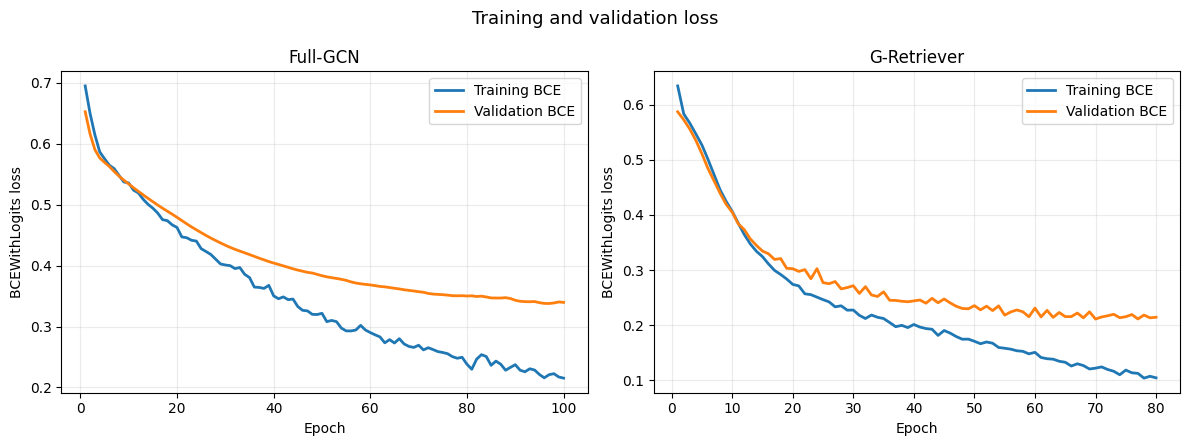

In [11]:
# Plot training and validation BCE loss across the epochs completed by each model
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name, history in zip(axes, ['Full-GCN', 'G-Retriever'], [full_gcn_history, gretriever_history]):
    ax.plot(history['epoch'], history['train_loss'], label='Training BCE', linewidth=2)
    ax.plot(history['epoch'], history['val_loss'], label='Validation BCE', linewidth=2)
    ax.set(title=name, xlabel='Epoch', ylabel='BCEWithLogits loss')
    ax.grid(True, alpha=0.25)
    ax.legend()
fig.suptitle('Training and validation loss', fontsize=13)
fig.tight_layout()
plt.show()

## Compare the two models

We compare test exact-pair accuracy, class overlap, learnable parameter counts, and total training time (seconds). Time is measured around each training-function call, including validation and final evaluation but excluding PCST retrieval and frozen LM embedding preparation.

**Evaluation metrics:** Let $P_i$ be the true unordered pair of bridge classes and $\widehat P_i$ the predicted pair for each of $n_\textrm{test}$ evaluated papers :

$$
\mathrm{ExactPair}=\frac{1}{n_\textrm{test}}\sum_{i=1}^{n_\textrm{test}}\mathbf{1}[\widehat P_i=P_i],
\qquad
\mathrm{ClassOverlap}=\frac{1}{n_\textrm{test}}\sum_{i=1}^{n_\textrm{test}}\frac{|\widehat P_i\cap P_i|}{2}.
$$

Exact-pair accuracy counts a result as correct only when both*classes match. Class overlap gives 0, 0.5 or 1 for example, depending on how many of the two classes are recovered.

<table align="center"> <tr> <td align="center"> <img src="pic/pair_metrics.png" width="700"> </td> </tr> </table>


In [12]:
# Compare accuracy, class overlap, learnable parameters and total training-function runtime
full_gcn_row = {'model': 'Full-GCN', 'evidence': 'BoW + Title/Abs + Anchor nodes '}
full_gcn_row.update(test_exact_pair=full_test, test_class_overlap=full_overlap, trainable_parameters=full_gcn_num_params, training_time_seconds=round(full_gcn_training_time_s, 2))
gretriever_row = {'model': 'G-Retriever', 'evidence': 'Structural Feat + PCST + Prompt'}
gretriever_row.update(test_exact_pair=rag_test, test_class_overlap=rag_overlap, trainable_parameters=gretriever_num_params, training_time_seconds=round(gretriever_training_time_s, 2))
results = pd.DataFrame([full_gcn_row, gretriever_row])
results.style.format({'test_exact_pair': '{:.4f}', 'test_class_overlap': '{:.4f}', 'trainable_parameters': '{:,}', 'training_time_seconds': '{:.2f}'})


,model,evidence,test_exact_pair,test_class_overlap,trainable_parameters,training_time_seconds
0,Full-GCN,BoW + Title/Abs + Anchor nodes,0.6193,0.7919,"154,119",2.13
1,G-Retriever,Structural Feat + PCST + Prompt,0.7005,0.8503,"189,173",15.62
